# Feature importance: what does the risk model rely on?
**Helen Valdez · CAP 3764 · Fall 2026**

This notebook completes Helen's feature-importance assignment in `docs/MODELING_NOTES.md`. We use the team's gradient boosting pipeline and the same train/test split as notebook 04. We compare all predictors with a prespecified reduced set excluding `Debt_Equity_Ratio`, `Cash_Flow`, and `Total_Liabilities`. These exclusions follow the team brief; this notebook does not establish the label-generation rule or tune a model.

Run with **Python (cap3764-risk)** from the repository root or `notebooks/`, after running the shared collection and cleaning modules. The two charts are saved under `reports/figures/feature_importance_*.png`.

## 1. Load the data and reuse the team's split
The shared package supplies loading, identifier removal, splitting, pipelines, and evaluation. Reusing it keeps this analysis consistent with Pablo's notebook. Models fit on training rows only; the test rows are used for evaluation and interpretation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score

from risk_data import modeling as m

root = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / "pyproject.toml").exists()), None)
if root is None:
    raise FileNotFoundError("Run from the repository root or notebooks folder")
figure_dir = root / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="colorblind")

RANDOM_STATE = m.RANDOM_STATE
N_REPEATS = 20
excluded = ["Debt_Equity_Ratio", "Cash_Flow", "Total_Liabilities"]
df = m.load_model_data(root / "data" / "processed" / "cleaned_data.csv")
assert not df.isna().any().any(), "Review missing-value handling before modeling"
assert df["Company_ID"].is_unique, "Repeated companies require a group-aware split"
assert set(df[m.TARGET].unique()) == {0, 1}, "Expected binary risk labels"
X, y = m.split_features(df)
assert not set([m.TARGET, *m.IDENTIFIER_COLUMNS]) & set(X.columns)
assert set(excluded).issubset(X.columns)
X_train, X_test, y_train, y_test = m.make_train_test_split(X, y)
assert set(X_train.index).isdisjoint(X_test.index)
display(pd.DataFrame({
    "Records": [len(y_train), len(y_test)],
    "At-risk records": [int(y_train.sum()), int(y_test.sum())],
    "At-risk share": [y_train.mean(), y_test.mean()],
}, index=["Training", "Test"]))

,Records,At-risk records,At-risk share
Training,2860,460,0.160839
Test,715,115,0.160839


## 2. Fit the two prespecified models
**All features:** the original financial, macroeconomic, and sector predictors.

**Reduced features:** the same rows with the three inputs named in the team brief removed. We refit the pipeline for this feature set; simply deleting columns from a fitted model would not be a fair comparison. The reduced model may still use proxies, such as `Net_Income` for `Cash_Flow`, so removal does not prove leakage is eliminated.

Average precision (AP) summarizes the precision–recall curve and emphasizes the minority at-risk class. It is the `average_precision` score requested by the brief and called PR-AUC by the shared module; it is not trapezoidal integration of the curve. A constant-score baseline has AP equal to the test-set positive share.

In [2]:
feature_sets = {
    "All features": X_train.columns.tolist(),
    "Reduced features": [c for c in X_train.columns if c not in excluded],
}
fitted = {}
metric_rows = {}
for name, columns in feature_sets.items():
    model = m.build_models(X_train[columns], random_state=RANDOM_STATE)["gradient_boosting"]
    model.fit(X_train[columns], y_train)
    fitted[name] = model
    metric_rows[name] = m.evaluate(model, X_test[columns], y_test)
metrics = pd.DataFrame.from_dict(metric_rows, orient="index").rename(columns={"pr_auc": "average_precision"})
metrics["Predictor count"] = [len(feature_sets[name]) for name in metrics.index]
display(metrics)
no_skill_ap = average_precision_score(y_test, np.full(len(y_test), y_train.mean()))
print(f"Constant-score test AP: {no_skill_ap:.6f}")
print("Excluded from the reduced model:", ", ".join(excluded))

,precision,recall,f1,roc_auc,average_precision,Predictor count
All features,1.000000,0.991304,0.995633,1.000000,1.000000,17
Reduced features,0.393939,0.226087,0.287293,0.606696,0.378448,14


Constant-score test AP: 0.160839
Excluded from the reduced model: Debt_Equity_Ratio, Cash_Flow, Total_Liabilities


## 3. Measure importance by shuffling test-set columns
For each fitted pipeline, keep the model fixed and shuffle one original input column at a time. Importance is **baseline test AP minus AP after shuffling**. Repeat each shuffle 20 times with a fixed seed; report the mean and standard deviation of those drops.

A large positive drop means the fitted model relies on that input. A value near zero means little measured reliance in this model; a negative value means shuffling improved its score. The bars are not percentages of total importance. The error bars show shuffle variability on this fixed test set, not confidence intervals or uncertainty across future samples. Because permutation happens before preprocessing, sector is treated as one original column rather than separate encoded categories.

In [3]:
importance_tables = {}
for name, columns in feature_sets.items():
    result = permutation_importance(
        fitted[name], X_test[columns], y_test,
        scoring="average_precision", n_repeats=N_REPEATS,
        random_state=RANDOM_STATE, n_jobs=1,
    )
    table = pd.DataFrame({
        "Feature": columns,
        "Mean AP drop": result.importances_mean,
        "Shuffle SD": result.importances_std,
    }).sort_values("Mean AP drop", ascending=False).reset_index(drop=True)
    assert np.isfinite(table[["Mean AP drop", "Shuffle SD"]].to_numpy()).all()
    importance_tables[name] = table
    display(Markdown(f"### {name}"))
    display(table)

### All features

,Feature,Mean AP drop,Shuffle SD
0,Debt_Equity_Ratio,7.716057e-01,1.629597e-02
1,Cash_Flow,2.223969e-02,2.336340e-03
2,Net_Income,2.545382e-03,1.766597e-04
3,Inflation_Rate,1.776357e-16,1.377751e-16
4,GDP_Growth_Rate,1.720846e-16,1.425027e-16
5,Return_on_Assets,1.665335e-16,9.614813e-17
6,Volatility_Index,1.665335e-16,1.665335e-16
7,Revenue,1.554312e-16,1.285176e-16
8,Current_Assets,1.443290e-16,1.221245e-16
9,Stock_Price_Close,1.443290e-16,1.169693e-16


### Reduced features

,Feature,Mean AP drop,Shuffle SD
0,Net_Income,0.214283,0.008850
1,Return_on_Assets,0.006410,0.003870
2,GDP_Growth_Rate,0.002644,0.007157
3,Volatility_Index,0.002269,0.007743
4,Total_Assets,0.001644,0.006629
5,Current_Assets,-0.000031,0.005498
6,Industry_Sector,-0.000736,0.002307
7,Revenue,-0.003071,0.006068
8,Inflation_Rate,-0.004991,0.011542
9,Stock_Price_Close,-0.005317,0.006747


## 4. Visual comparison
Each chart includes all inputs available to that model. The panels use their own horizontal scales to keep smaller drops readable; compare the numbers rather than bar lengths across separate charts. A model with a much lower baseline AP has less performance to lose, so importance magnitudes depend on the model and its starting score.

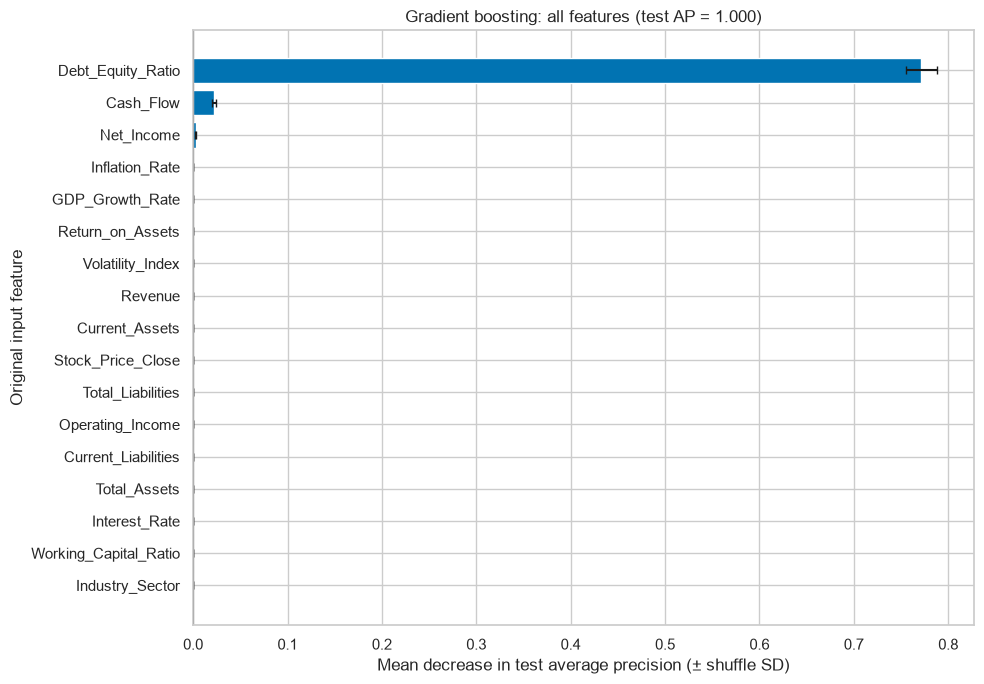

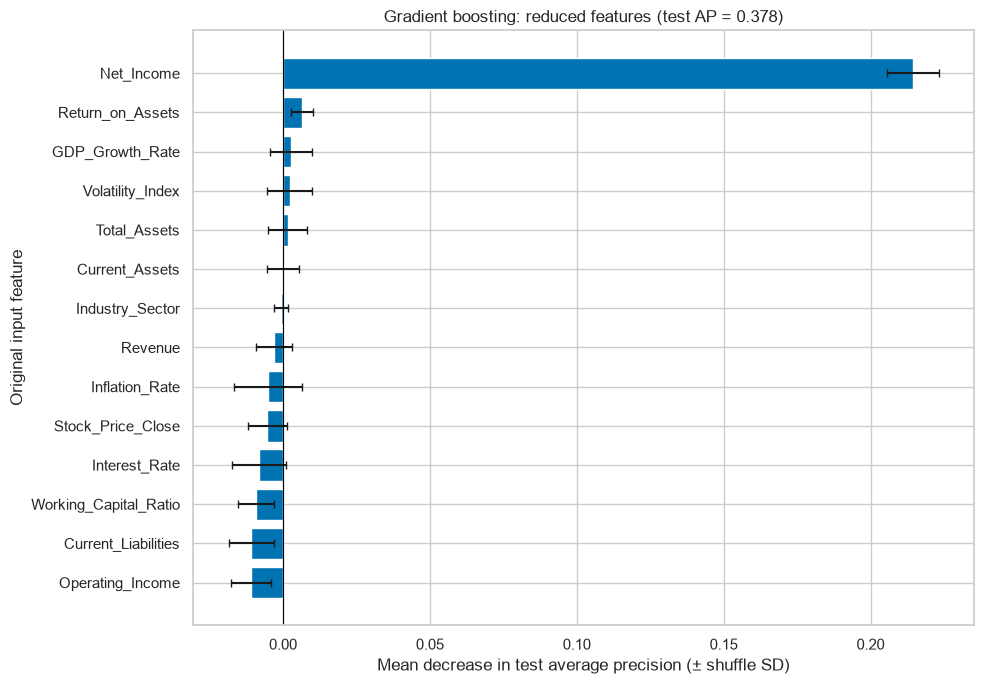

In [4]:
for name, table in importance_tables.items():
    ordered = table.sort_values("Mean AP drop", ascending=True)
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(ordered["Feature"], ordered["Mean AP drop"],
            xerr=ordered["Shuffle SD"], capsize=3,
            color=sns.color_palette("colorblind")[0])
    ax.axvline(0, color="black", linewidth=0.8)
    baseline = metrics.loc[name, "average_precision"]
    ax.set(title=f"Gradient boosting: {name.lower()} (test AP = {baseline:.3f})",
           xlabel="Mean decrease in test average precision (± shuffle SD)",
           ylabel="Original input feature")
    fig.tight_layout()
    suffix = "all" if name == "All features" else "reduced"
    fig.savefig(figure_dir / f"feature_importance_{suffix}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 5. Interpretation for a business reader
The five sentences below are calculated from this run's results. They describe the model's behavior in this dataset, not causes of distress or validated future-risk drivers.

In [5]:
top_all = importance_tables["All features"].iloc[0]
top_reduced = importance_tables["Reduced features"].iloc[0]
all_ap = metrics.loc["All features", "average_precision"]
reduced_ap = metrics.loc["Reduced features", "average_precision"]
sentences = [
    f"With all features, gradient boosting has test average precision {all_ap:.3f}, and shuffling {top_all['Feature']} produces the largest mean score decrease ({top_all['Mean AP drop']:.3f}).",
    f"After excluding {', '.join(excluded)}, the refitted model has test average precision {reduced_ap:.3f}, compared with {no_skill_ap:.3f} for a constant-score baseline.",
    f"In the reduced model, the largest mean decrease comes from {top_reduced['Feature']} ({top_reduced['Mean AP drop']:.3f}, shuffle standard deviation {top_reduced['Shuffle SD']:.3f}); this is a ranking of measured model reliance, not proof of a stable business driver.",
    "For a business reader, the all-features model may be reconstructing how risk labels were assigned, while the reduced model can still exploit related proxy variables.",
    "These findings describe associations in the sampled companies and need the team's label-sensitivity analysis and external or later-period validation before being used to forecast financial distress.",
]
display(Markdown(" ".join(sentences)))

With all features, gradient boosting has test average precision 1.000, and shuffling Debt_Equity_Ratio produces the largest mean score decrease (0.772). After excluding Debt_Equity_Ratio, Cash_Flow, Total_Liabilities, the refitted model has test average precision 0.378, compared with 0.161 for a constant-score baseline. In the reduced model, the largest mean decrease comes from Net_Income (0.214, shuffle standard deviation 0.009); this is a ranking of measured model reliance, not proof of a stable business driver. For a business reader, the all-features model may be reconstructing how risk labels were assigned, while the reduced model can still exploit related proxy variables. These findings describe associations in the sampled companies and need the team's label-sensitivity analysis and external or later-period validation before being used to forecast financial distress.

## 6. Limits and reproducibility
- **Correlated inputs:** shuffling can create unrealistic combinations, and related variables can substitute for one another. A small importance score does not show a feature is economically irrelevant. `Net_Income` and `Cash_Flow` are particularly relevant to the planned sensitivity analysis.
- **Test-set reuse:** notebook 04 already evaluated these test rows. This notebook uses them for post-hoc explanation of two prespecified models, not tuning or selecting a final model. Do not change features or parameters in response to these scores and then claim a new independent test result.
- **Prediction goal:** the target is the dataset's binary label, with no specified future horizon. Importance does not establish cause, direction of effect, default probability calibration, or future distress prediction.
- **Data preparation:** the current file has no missing values. The shared cleaner's full-data median fill would need revisiting if future data have missing values; learned imputation belongs inside training folds.
- **Repeatability:** reuse the package, the same split (`random_state=42`), and the fixed permutation settings above. Restart the kernel and run all cells. No new packages are required beyond the merged pinned environment, and no data are committed.

Lilly reviews this notebook under `docs/TEAM_WORKFLOW.md`. Label reconstruction and feature-exclusion sensitivity belong to Jorlfran's notebook 06; tuning belongs to Lilly's notebook 07.